# Milestone 4 — Fiabiliser la solution et analyser les gains

**Objectif (slide 8 du cours).** Le Milestone 4 a deux parties :

1. **Suites de tests et résultats des tests** :
   - tests unitaires des fonctions du moteur ;
   - respect des contraintes ;
   - cas limites et hypothèses sur les données manquantes ;
   - tous les matériaux livrés, et les besoins des usines servis à temps.
2. **Analyse comparative avant / après** :
   - nouvelles distributions du remplissage et des coûts ;
   - économies réalisées.

**Principe.** Les tests sont des fonctions du package
[`validation`](../src/delivery_schedule_optimization/validation/) de l'application :

- [`output_tests.py`](../src/delivery_schedule_optimization/validation/output_tests.py) : les tests sur les **fichiers de
  sortie** (A2 à A5). Ils ne passent pas par le moteur : ils testent ce qui est livré. L'application les rejoue à
  **chaque exécution** et écrit le résultat dans `tests_sorties.csv` ;
- [`engine_cases.py`](../src/delivery_schedule_optimization/validation/engine_cases.py) : les **cas unitaires du moteur**
  (A1, A3), sur de petits cas dont on connaît la réponse.

Les mêmes fonctions sont lancées par `pytest` (`tests/unit/test_engine_cases.py`, `tests/integration/test_output_tests.py`)
et par ce notebook, qui les présente et analyse les résultats.

## 0. Entrées

Le notebook lance l'application sur les **trois fichiers bruts**, comme `main.py run`, puis teste les sorties produites.

| Entrée | Fichier | Rôle |
|---|---|---|
| Planning publié | `docs/released_schedule.csv` | besoins (nettoyés et imputés par l'application, Milestone 1) |
| Distances | `docs/distances.csv` | distances des fournisseurs ; test de l'hypothèse H06 |
| Grille du transporteur | `courses/rate_sheet.pdf` | prix, marge et surcharge diesel ; recalcul des coûts |
| Sorties de référence (M3) | `tests/regression/expected/sortie*.csv` | reproductibilité |

In [1]:
from __future__ import annotations

import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from delivery_schedule_optimization.baseline.current import current_deliveries
from delivery_schedule_optimization.domain.calendar import public_holidays
from delivery_schedule_optimization.domain.config import PlannerConfig
from delivery_schedule_optimization.io.readers import read_distances, read_rate_sheet, read_schedule
from delivery_schedule_optimization.io.schemas import OutputName
from delivery_schedule_optimization.pipeline import RawInputs, RunConfig, run_pipeline
from delivery_schedule_optimization.preparation.lines import prepare_lines
from delivery_schedule_optimization.pricing.tariff import Tariff, rate_grid
from delivery_schedule_optimization.validation import engine_cases, output_tests as ot

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)-7s %(message)s", datefmt="%H:%M:%S", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)

ROOT = Path("..")
EXPECTED_DIR = ROOT / "tests" / "regression" / "expected"  # outputs of the milestone 3 notebook
RUN_ENGINE_TWICE = True  # False = skip the second run of the reproducibility test (about 15 s)
cfg = PlannerConfig()
pd.set_option("display.max_colwidth", 120)

### Exécution de l'application

Une exécution complète : préparation des données, situation actuelle, plans candidats, lissage, sorties, contrôles et
tests de sortie.

In [2]:
raw = RawInputs(schedule=read_schedule(ROOT / "docs" / "released_schedule.csv"),
                distances=read_distances(ROOT / "docs" / "distances.csv"),
                rate_sheet=read_rate_sheet(ROOT / "courses" / "rate_sheet.pdf"))
result = run_pipeline(raw, RunConfig(planner=cfg))

lines = prepare_lines(result.tables[OutputName.CONSOLIDATED], cfg)  # the lines as planned (line_id, imputed_full_truck)
tariff = Tariff(rate_grid(raw.rate_sheet.table), raw.rate_sheet.price_factor)
holidays = public_holidays(lines, cfg)
deliveries_before, trucks_before = current_deliveries(lines, tariff, cfg)  # reference A, truck by truck

profiles = result.tables[OutputName.PROFILES]
trucks = result.tables[OutputName.TRUCKS]
alloc = result.tables[OutputName.ALLOCATIONS]
contents = result.tables[OutputName.TRUCK_CONTENTS]
saving = result.tables[OutputName.SAVING]
run = ot.RunTables(lines=lines, distances=raw.distances, deliveries_before=deliveries_before, profiles=profiles,
                   trucks=trucks, allocations=alloc, contents=contents, saving=saving)
inputs = engine_cases.EngineInputs(lines=lines, holidays=holidays, tariff=tariff, config=cfg)

pd.DataFrame({"lignes": {"dataset consolidé": len(lines), "sortie 1 - profils": len(profiles), "sortie 2 - camions": len(trucks),
                         "sortie 2 - affectations": len(alloc), "sortie 2 - contenu": len(contents), "sortie 3 - saving": len(saving)}})

17:32:36 INFO    released_schedule: 5728 rows x 10 columns


17:32:36 INFO    distances: 156 rows x 2 columns


17:32:36 INFO    rate_sheet: worked example of the PDF recomputed (300 km, 1000 kg: 82.77 EUR -> 335.34 EUR)


17:32:36 INFO    rate_sheet: PDF grid 14 distance x 15 weight brackets, margin 239.23 %, diesel 1.1943, valid from 01.08.2026


17:32:36 INFO    Stage preparation: started


17:32:36 INFO    DQ01 [schedule] 959 row(s) - dropped (quantity = 0, no need)


... (23 outputs left out)

17:32:46 INFO    Output tests: 24 passed


17:32:46 INFO    Stage checks: 0.2 s


17:32:46 INFO    Run done: cost 176725 -> 110458 EUR (saving 37.5 %), 1741 -> 757 trucks


,lignes
dataset consolidé,4389
sortie 1 - profils,180
sortie 2 - camions,757
sortie 2 - affectations,4389
sortie 2 - contenu,2966
sortie 3 - saving,180


### Registre des tests

**Chaque test est une fonction** `test_...` :
- elle prend en paramètres les données qu'elle contrôle ;
- elle renvoie `(True, détail)` si la règle est respectée, sinon `(False, détail)` ;
- la première ligne de sa docstring est le libellé du test.

On peut donc rejouer une fonction sur une autre sortie, par exemple une sortie volontairement cassée (section A2).

`ot.run_test` exécute une fonction, attrape les erreurs (un test qui plante est un test en échec) et renvoie une ligne de
résultat. `RESULTS` garde toutes les lignes ; la synthèse (section A6) le lit.

In [3]:
RESULTS: list[dict[str, object]] = []
OUTPUT_TESTS = ot.output_tests(run, holidays, tariff, cfg)


def run_suite(suite: str) -> pd.DataFrame:
    """Run every test of one suite (engine cases and output tests), record and show the results."""
    rows = [ot.run_test(s, fn, *engine_cases.case_arguments(names, inputs)) for s, fn, names in engine_cases.CASES if s == suite]
    rows += [ot.run_test(s, fn, *args) for s, fn, args in OUTPUT_TESTS if s == suite]
    RESULTS.extend(rows)
    return pd.DataFrame(rows).drop(columns="suite")

# Partie A — Suites de tests

## A1. Tests unitaires des fonctions du moteur

Chaque fonction du moteur est testée sur un **petit cas construit à la main** dont on connaît la réponse : calendrier,
fenêtre de livraison d'un besoin, chargement d'un camion, et la recherche locale `reassign`, qui ne doit jamais dégrader
un plan (10 plus gros couples × 15 ensembles de 1 ou 2 jours).

Depuis la réponse du client, le plan commence **7 jours avant le premier besoin** : chaque jour de besoin a toujours un jour
de chaque profil dans sa fenêtre (`test_every_need_has_a_profile_day`), et il n'y a plus de départ de démarrage.

In [4]:
run_suite("A1 - unitaires")

,fonction,test,respecté,détail
0,test_saturday_is_not_a_working_day,is_working_day : un samedi n'est pas ouvré,True,samedi 21/11
1,test_christmas_is_a_holiday,is_working_day : le 25/12 est férié en Allemagne,True,vendredi 25/12
2,test_first_working_day_after_a_saturday,first_working_day : un samedi donne le lundi suivant,True,23/11
3,test_window_of_a_monday_profile,"delivery_options : besoin du vendredi 20/11, profil lundi → livré le lundi 16/11",True,"[(datetime.date(2026, 11, 16), datetime.date(2026, 11, 16))]"
4,test_window_of_7_days,"delivery_options : aucune option à plus de 7 jours d'avance, ni après la date du besoin",True,"avances possibles [0, 1, 2, 3, 4, 7] j"
5,test_every_need_has_a_profile_day,"delivery_options : avec 7 jours d'avance, chaque jour de besoin a une option pour chacun des 5 profils d'un jour",True,0 besoin(s) sans jour de profil dans leur fenêtre
6,test_pack_two_trucks,"pack : capacité respectée, chaque ligne une fois, nombre de camions minimal (2)",True,"2 camions : [[np.int64(0), np.int64(2), np.int64(3)], [np.int64(1)]]"
7,test_reassign_never_worse,"reassign : n'augmente jamais le coût d'un plan et garde un plan valide (fenêtre, capacité, mêmes lignes)",True,"150 plans testés, 102 améliorés, aucun dégradé"


## A2. Respect des contraintes, recalculé à partir des fichiers de sortie

**Une fonction par contrainte.** Chacune prend les tables de sortie en paramètres et ne passe pas par le moteur : on teste
ce qui est livré. En plus des règles RG01 à RG11 :
- **Profil** : chaque couple livre sur les jours de son profil, et **chaque besoin** part un jour de son profil (ou le jour
  ouvré précédent si ce jour est férié), sans exception ;
- **Début du plan** : aucune livraison avant le premier jour ouvré du plan (02/11) ;
- **Sortie 2** : le contenu des camions correspond exactement aux affectations.

In [5]:
run_suite("A2 - contraintes")

,fonction,test,respecté,détail
0,test_rg01_one_couple_per_truck,RG01 - un seul couple fournisseur × usine par camion,True,0 camion(s) mélangent deux couples
1,test_rg02_never_late,RG02 - aucune livraison après la date de besoin,True,0 ligne(s) en retard
2,test_rg03_max_advance,RG03 - avance ≤ 7 jours calendaires,True,avance maximale 7 j
3,test_rg03_advance_column,RG03 - la colonne advance_days = need_date − delivery_date,True,0 ligne(s) incohérente(s)
4,test_rg04_weight,RG04 - poids ≤ 24 500 kg par camion (recalculé à partir des lignes),True,camion le plus lourd 24 500 kg
5,test_rg04_volume,"RG04 - volume ≤ 110,4 m³ par camion (recalculé à partir des lignes)",True,camion le plus volumineux 110.4 m³
6,test_rg05_allowed_profiles,RG05 - le profil de chaque couple fait partie des profils autorisés,True,0 couple(s) hors des profils autorisés
7,test_rg10_working_days,RG10 - aucune livraison un week-end ou un jour férié,True,0 camion(s) un jour non ouvré
8,test_rg11_truck_cost,"RG11 - coût de chaque camion = grille(distance, poids) × (1 + marge) × diesel",True,0 camion(s) mal payés
9,test_rg11_truck_totals,"RG11 - poids, volume et nombre de lignes de chaque camion = somme de ses lignes",True,757 camions comparés


### Les tests détectent-ils vraiment une violation ?

Un test qui renvoie toujours `True` ne prouve rien. On casse donc volontairement une copie de la sortie et on vérifie que
chaque fonction répond `False`. Les mêmes cas sont rejoués par `pytest` (`tests/integration/test_output_tests.py`).

In [6]:
first = alloc.index[0]
early = alloc.copy()
early.loc[first, "delivery_date"] = early.loc[first, "need_date"] - pd.Timedelta(days=cfg.max_advance_days + 1)
late = alloc.copy()
late.loc[first, "delivery_date"] = late.loc[first, "need_date"] + pd.Timedelta(days=1)
biggest = alloc.groupby("truck_id").size().idxmax()
heavy = alloc.copy()
heavy.loc[heavy["truck_id"].eq(biggest), "weight"] = cfg.truck_kg  # biggest truck: every line at 24.5 t
mixed = alloc.copy()
mixed.loc[first, "truck_id"] = alloc.loc[alloc["supplier_id"] != alloc.loc[first, "supplier_id"], "truck_id"].iloc[0]
overpaid = trucks.assign(cost=trucks["cost"] * 1.01)
material = (alloc["plant"] == alloc.loc[first, "plant"]) & (alloc["material"] == alloc.loc[first, "material"])
all_late = alloc.copy()
all_late.loc[material, "delivery_date"] = all_late.loc[material, "need_date"] + pd.Timedelta(days=1)  # one material, always late

pd.DataFrame({"détecte la violation": {
    "RG01 - ligne mise dans le camion d'un autre fournisseur": not ot.test_rg01_one_couple_per_truck(mixed)[0],
    "RG02 - ligne livrée 1 jour en retard": not ot.test_rg02_never_late(late)[0],
    "RG03 - ligne livrée 8 jours en avance": not ot.test_rg03_max_advance(early, cfg.max_advance_days)[0],
    "RG04 - camion surchargé": not ot.test_rg04_weight(heavy, cfg.truck_kg)[0],
    "RG08 - ligne livrée deux fois": not ot.test_each_line_delivered_once(pd.concat([alloc, alloc.head(1)]))[0],
    "RG11 - camion payé 1 % trop cher": not ot.test_rg11_truck_cost(overpaid, tariff)[0],
    "Anticipation - un matériel toujours livré 1 jour en retard": not ot.test_no_stock_out(all_late)[0],
}})

,détecte la violation
RG01 - ligne mise dans le camion d'un autre fournisseur,True
RG02 - ligne livrée 1 jour en retard,True
RG03 - ligne livrée 8 jours en avance,True
RG04 - camion surchargé,True
RG08 - ligne livrée deux fois,True
RG11 - camion payé 1 % trop cher,True
Anticipation - un matériel toujours livré 1 jour en retard,True


## A3. Cas limites et hypothèses sur les données manquantes

- **H05** : une ligne de poids ou de volume inconnu est complétée par un camion plein ; elle voyage donc seule, et une ligne
  de 24 500 kg exactement tient dans un camion ;
- **H06** : un fournisseur sans distance reçoit la plus longue distance des fournisseurs du planning (SUP_00130, 149 km) ;
- **RG10** : un jour férié fictif dans la semaine ;
- un couple avec une seule ligne ;
- **la première semaine** : un besoin du lundi 09/11 pour un couple livré le mercredi part le mercredi 04/11, sur son profil.

In [7]:
run_suite("A3 - cas limites")

,fonction,test,respecté,détail
0,test_full_line_fits_one_truck,H05 - une ligne de 24 500 kg exactement tient dans un seul camion,True,1 camion(s)
1,test_fictitious_holiday,"RG10 - un férié fictif le mardi 17/11 (profil mardi) : la livraison est avancée au lundi 16/11, dans la fenêtre",True,37 ligne(s) de la semaine du 17/11 livrée(s) le 2026-11-16
2,test_couple_with_one_line,"Couple d'une seule ligne : chaque plan candidat a un seul camion, un profil 1 et le prix de la grille",True,"5 plan(s) candidat(s), prix attendu 43.51 EUR"
3,test_first_week_on_the_profile,Début du plan - un besoin du lundi 09/11 pour un couple livré le mercredi part le mercredi 04/11 (aucun démarrage),True,besoin du 09/11 livré le 04/11


In [8]:
run_suite("A3 - données manquantes")

,fonction,test,respecté,détail
0,test_h05_imputed_line_alone,H05 - une ligne imputée « camion plein » voyage seule dans son camion,True,"134 camion(s) avec une ligne imputée, 0 partagé(s)"
1,test_h06_imputed_distance,H06 - un fournisseur sans distance reçoit la plus longue distance des fournisseurs connus du planning,True,SUP_00130 : 149 km attendus (dataset et camions)


## A4. Exhaustivité des matériaux livrés et anticipation des besoins

On vérifie deux choses :
- chaque ligne du dataset est livrée une fois et une seule, avec la bonne quantité et sa date de besoin ;
- aucune usine n'est servie en retard : à chaque date, la quantité reçue cumulée couvre les besoins cumulés.

In [9]:
run_suite("A4 - exhaustivité")

,fonction,test,respecté,détail
0,test_each_line_delivered_once,RG08 - chaque ligne est livrée une seule fois,True,0 doublon(s)
1,test_no_line_forgotten,RG08 - aucune ligne du dataset n'est oubliée,True,0 ligne(s) non livrée(s)
2,test_quantities,"RG08 - quantité livrée = quantité demandée, par usine × matériel",True,0 usine × matériel avec une quantité différente
3,test_need_dates,La date de besoin de chaque ligne livrée = la date du dataset,True,0 date(s) de besoin modifiée(s)
4,test_no_stock_out,"Anticipation - à chaque date, quantité reçue cumulée ≥ besoins cumulés (usine × matériel)",True,0 jour(s) en rupture


## A5. Cohérence du saving et reproductibilité

Principe de la slide 11 : même entrée + mêmes paramètres = mêmes résultats.
- les coûts avant et après de la sortie 3 sont ceux de la situation actuelle et des camions de la sortie 2 ;
- les sorties de l'application sont **identiques, au caractère près, à celles du notebook du Milestone 3**
  (`tests/regression/expected/`, le même contrôle que le test de non-régression) ;
- une seconde exécution donne les mêmes tables (désactivable avec `RUN_ENGINE_TWICE = False`).

In [10]:
def test_same_outputs_as_milestone_3(tables: dict[OutputName, pd.DataFrame], expected_dir: Path) -> ot.TestOutcome:
    """Reproductibilité - les sorties 1, 2 et 3 sont identiques à celles du notebook du Milestone 3"""
    names = [OutputName.PROFILES, OutputName.TRUCKS, OutputName.ALLOCATIONS, OutputName.TRUCK_CONTENTS, OutputName.SAVING]
    different = [name.value for name in names
                 if tables[name].to_csv(index=False).replace("\r\n", "\n")
                 != (expected_dir / f"{name.value}.csv").read_text(encoding="utf-8").replace("\r\n", "\n")]
    return not different, f"{len(names) - len(different)} / {len(names)} fichiers identiques {different or ''}"


def test_second_run_identical(raw: RawInputs, config: PlannerConfig, tables: dict[OutputName, pd.DataFrame]) -> ot.TestOutcome:
    """Reproductibilité - une seconde exécution donne les mêmes camions, le même coût et les mêmes dates de livraison"""
    again = run_pipeline(raw, RunConfig(planner=config)).tables
    names = [OutputName.PROFILES, OutputName.TRUCKS, OutputName.ALLOCATIONS]
    same = all(again[name].equals(tables[name]) for name in names)
    return same, f"{len(again[OutputName.TRUCKS])} camions, {again[OutputName.TRUCKS]['cost'].sum():,.2f} EUR".replace(",", " ")


S = "A5 - saving et reproductibilité"
rows = [ot.run_test(S, fn, *args) for s, fn, args in OUTPUT_TESTS if s == "A5 - saving"]
rows.append(ot.run_test(S, test_same_outputs_as_milestone_3, result.tables, EXPECTED_DIR))
if RUN_ENGINE_TWICE:
    rows.append(ot.run_test(S, test_second_run_identical, raw, cfg, result.tables))
RESULTS.extend(rows)
pd.DataFrame(rows).drop(columns="suite")

17:32:48 INFO    Stage preparation: started


17:32:48 INFO    DQ01 [schedule] 959 row(s) - dropped (quantity = 0, no need)


17:32:48 INFO    DQ01 [schedule] 0 row(s) - dropped (negative quantity)


17:32:48 INFO    DQ01 [schedule] 0 row(s) - dropped (missing quantity)


17:32:48 INFO    DQ03 [schedule] 379 row(s) - dropped (date >= 2027-01-01, needs accumulated after the horizon)


17:32:48 INFO    DQ02 [schedule] 0 row(s) - flagged and kept (no delivery on weekends, handled by the optimization)


... (19 outputs left out)

17:33:01 INFO    Output tests: 24 passed


17:33:01 INFO    Stage checks: 0.3 s


17:33:01 INFO    Run done: cost 176725 -> 110458 EUR (saving 37.5 %), 1741 -> 757 trucks


,fonction,test,respecté,détail
0,test_cost_before,Sortie 3 - coût avant = situation actuelle recalculée camion par camion,True,176 724.61 EUR (situation actuelle 176 724.61 EUR)
1,test_cost_after,Sortie 3 - coût après = somme des camions de la sortie 2,True,110 457.86 EUR (camions 110 457.86 EUR)
2,test_same_outputs_as_milestone_3,"Reproductibilité - les sorties 1, 2 et 3 sont identiques à celles du notebook du Milestone 3",True,5 / 5 fichiers identiques
3,test_second_run_identical,"Reproductibilité - une seconde exécution donne les mêmes camions, le même coût et les mêmes dates de livraison",True,757 camions 110 457.86 EUR


## A6. Synthèse des tests

In [11]:
summary = pd.DataFrame(RESULTS)
display(summary.groupby("suite")["respecté"].value_counts().unstack(fill_value=0).rename(columns={True: "OK", False: "ÉCHEC"}))
failed = summary[~summary["respecté"]]
display(failed if len(failed) else Markdown(f"**Les {len(summary)} tests passent.**"))
assert failed.empty, f"{len(failed)} test(s) en échec"

respecté,OK
suite,
A1 - unitaires,8
A2 - contraintes,15
A3 - cas limites,4
A3 - données manquantes,2
A4 - exhaustivité,5
A5 - saving et reproductibilité,4


**Les 38 tests passent.**

# Partie B — Analyse comparative avant / après

## B1. Indicateurs avant / après

In [12]:
before, after = trucks_before, trucks
kpis = pd.DataFrame({
    "avant (référence)": {"livraisons": len(deliveries_before), "camions": len(before), "coût (EUR)": before["cost"].sum(),
                          "remplissage moyen": before["fill"].mean(), "coût moyen / camion (EUR)": before["cost"].mean()},
    "après (plan retenu)": {"livraisons": after.groupby(["supplier_id", "plant", "date"]).ngroups, "camions": len(after),
                            "coût (EUR)": after["cost"].sum(), "remplissage moyen": after["fill"].mean(),
                            "coût moyen / camion (EUR)": after["cost"].mean()},
})
kpis["écart"] = kpis.iloc[:, 1] - kpis.iloc[:, 0]
kpis["écart (%)"] = 100 * kpis["écart"] / kpis.iloc[:, 0]
kpis.round(2)

,avant (référence),après (plan retenu),écart,écart (%)
livraisons,1665.00,644.00,-1021.00,-61.32
camions,1741.00,757.00,-984.00,-56.52
coût (EUR),176724.61,110457.86,-66266.75,-37.50
remplissage moyen,0.12,0.27,0.15,129.35
coût moyen / camion (EUR),101.51,145.92,44.41,43.75


## B2. Nombre de couples par classe de profil, avant / après

- **Avant** : profil actuel du couple (`current_profile` de la sortie 1), soit le plus grand nombre de livraisons faites en une
  semaine aujourd'hui.
- **Après** : profil retenu par le moteur.

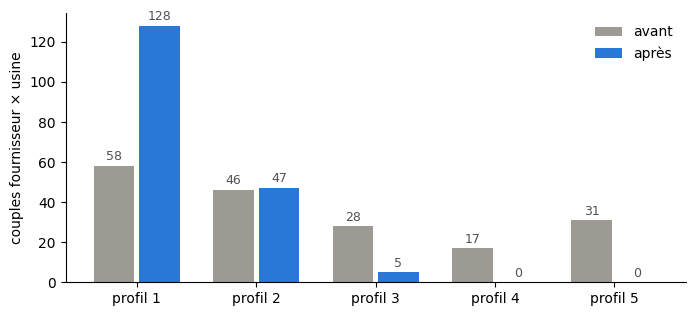

,1,2,3,4,5,total
avant,58,46,28,17,31,180
après,128,47,5,0,0,180


In [13]:
classes = range(1, 6)
counts = pd.DataFrame({"avant": profiles["current_profile"].value_counts(),
                       "après": profiles["profile"].value_counts()}).reindex(classes).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8, 3.5))
x, width = np.arange(len(counts)), 0.38
for shift, column, color in ((-width / 2, "avant", "#9c9a92"), (width / 2, "après", "#2a78d6")):
    bars = ax.bar(x + shift, counts[column], width - 0.04, color=color, label=column)
    ax.bar_label(bars, fmt="%d", padding=2, fontsize=9, color="#52514e")
ax.set_xticks(x, [f"profil {k}" for k in counts.index])
ax.set_ylabel("couples fournisseur × usine")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()
counts.T.assign(total=lambda d: d.sum(axis=1))

## B3. Distribution du taux de remplissage

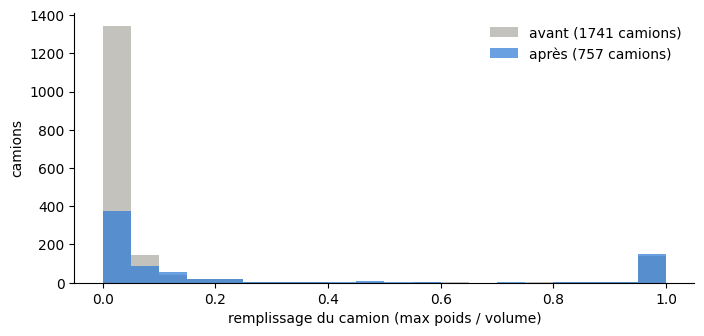

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 21)
ax.hist(before["fill"].clip(upper=1), bins=bins, alpha=0.6, label=f"avant ({len(before)} camions)", color="#9c9a92")
ax.hist(after["fill"].clip(upper=1), bins=bins, alpha=0.7, label=f"après ({len(after)} camions)", color="#2a78d6")
ax.set_xlabel("remplissage du camion (max poids / volume)")
ax.set_ylabel("camions")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## B4. Camions placés sur la grille tarifaire, avant / après

Chaque case de la grille est une tranche de distance × une tranche de poids. La couleur donne le **nombre de camions** qui
tombent dans cette case, avec la même échelle pour les deux graphes. Une consolidation réussie fait glisser les camions vers la
droite (tranches de poids élevées) : moins de camions, plus chargés.

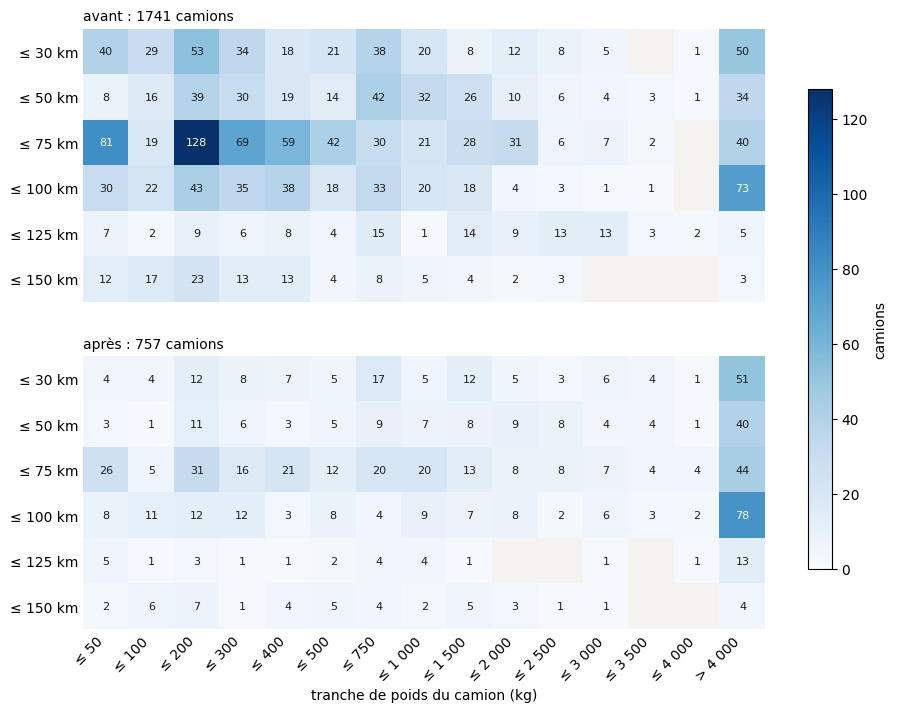

In [15]:
def grid_counts(frame: pd.DataFrame) -> pd.DataFrame:
    """Number of trucks per (distance bracket, weight bracket) of the rate sheet, read like the Tariff."""
    row = np.searchsorted(tariff.km, frame["distance"].to_numpy(float), side="left")
    col = np.searchsorted(tariff.kg, frame["weight"].to_numpy(float), side="left")
    return pd.crosstab(row, col).reindex(index=range(len(tariff.km)), columns=range(len(tariff.kg)), fill_value=0)


def bound(value: float, bounds: np.ndarray) -> str:
    return f"> {bounds[-2]:,.0f}".replace(",", " ") if np.isinf(value) else f"≤ {value:,.0f}".replace(",", " ")


grids = {"avant": grid_counts(trucks_before), "après": grid_counts(trucks)}
used_rows = sorted(set().union(*(g.index[g.sum(axis=1) > 0] for g in grids.values())))
vmax = max(g.to_numpy().max() for g in grids.values())
cmap = plt.get_cmap("Blues").copy()
cmap.set_bad("#f4f3ef")

fig, axes = plt.subplots(2, 1, figsize=(11, 1.2 + 0.55 * len(used_rows) * 2), sharex=True)
for ax, (name, grid) in zip(axes, grids.items()):
    data = grid.loc[used_rows].to_numpy(float)
    image = ax.imshow(np.ma.masked_equal(data, 0), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for (i, j), value in np.ndenumerate(data):
        if value:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8, color="white" if value > vmax * 0.55 else "#1f1e1c")
    ax.set_yticks(range(len(used_rows)), [bound(tariff.km[r], tariff.km) + " km" for r in used_rows])
    ax.set_title(f"{name} : {int(data.sum())} camions", loc="left", fontsize=10)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[-1].set_xticks(range(len(tariff.kg)), [bound(v, tariff.kg) for v in tariff.kg], rotation=45, ha="right")
axes[-1].set_xlabel("tranche de poids du camion (kg)")
fig.colorbar(image, ax=axes, shrink=0.8, label="camions")
plt.show()

## B5. Économies réalisées

Le saving du plan retenu (sortie 3), au total et par usine. Aucun couple ne paie plus cher qu'aujourd'hui.

In [16]:
by_plant = saving.groupby("plant")[["cost_before", "cost_after", "saving"]].sum()
by_plant.loc["total"] = by_plant.sum()
by_plant["saving (%)"] = 100 * by_plant["saving"] / by_plant["cost_before"]
display(by_plant.round(2))
display(Markdown(f"**Saving réalisé : {saving['saving'].sum():,.0f} EUR**".replace(",", " ")
                 + f" ({100 * saving['saving'].sum() / saving['cost_before'].sum():.1f} %) ; "
                 + f"couples qui paient plus cher qu'aujourd'hui : {int((saving['saving'] < -1e-6).sum())}."))

,cost_before,cost_after,saving,saving (%)
plant,,,,
PLT_001,45200.68,27952.60,17248.09,38.16
PLT_002,45004.43,28764.50,16239.93,36.09
PLT_003,27931.81,19387.52,8544.29,30.59
PLT_004,58587.68,34353.24,24234.44,41.36
total,176724.61,110457.86,66266.75,37.50


**Saving réalisé : 66 267 EUR** (37.5 %) ; couples qui paient plus cher qu'aujourd'hui : 0.